# 01. 데이터 분석 · 전처리 · 기본 모델

**목적:** 15분 최대수요전력을 구간 중간에 더 정확히 예측할 수 있는지 확인한다.

1. 원본 데이터 확인 (IMDELD 변압기 1초 전력)
2. 시간대별 부하 패턴
3. 15분 구간 평균 분포와 평가용 목표전력
4. 학습 샘플 만들기 (`features.py`)
5. 기존 계산식의 한계 확인 (구간 경과 시간별 오차)
6. 기본 모델 (LightGBM 기본값) vs 기존 계산식

> 본 학습(모델 6개 + 앙상블)은 `train.py`에서 한다. 이 노트북은 그 전에 데이터를 이해하고 방향을 정하는 실험 기록이다.

In [1]:
import sys
print(sys.executable)

/home/gmlck/projects/power-edge/ml/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor

import features
from features import TAB_COLS

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.unicode_minus"] = False
# 한글 폰트가 깨지면: plt.rcParams["font.family"] = "NanumGothic"  (sudo apt install fonts-nanum)

## 1. 원본 데이터 확인

In [3]:
raw = pd.read_csv(features.CSV_PATH, nrows=5)
raw

,timestamp,active_power,reactive_power,apparent_power,current,voltage
0,2017-12-11 18:43:52-02,8.22051,213.575,213.733,0.031497,6816.27
1,2017-12-11 18:43:53-02,11.50870,213.423,213.733,0.031358,6818.05
2,2017-12-11 18:43:54-02,-6.57641,-207.053,207.157,0.030559,6815.92
3,2017-12-11 18:43:55-02,3.28821,213.708,213.733,0.031567,6818.64
4,2017-12-11 18:43:56-02,0.00000,213.733,213.733,0.031358,6816.72


In [4]:
# 1초 전력 -> 10초 평균 kW (replay.py 와 같은 배율)
steps, scale = features.load_csv_power()

print(f"기간      : {steps.index.min()} ~ {steps.index.max()}")
print(f"일수      : {steps.index.normalize().nunique()}일")
print(f"10초 칸 수: {len(steps):,}")
print(f"빈 칸 비율: {steps.isna().mean():.2%}")
print(f"규모 배율 : x{scale:.1f}")
steps.describe()

기간      : 2017-12-11 18:43:50 ~ 2018-04-03 18:48:40
일수      : 114일
10초 칸 수: 976,350
빈 칸 비율: 59.30%
규모 배율 : x1.9


count    397396.000000
mean        731.250061
std         546.080750
min           0.006693
25%          57.613705
50%         952.569702
75%        1259.564087
max        1643.039673
dtype: float64

**확인할 것**
- 빈 칸 비율: 수집 누락이 얼마나 되는지. 빈 칸이 있는 15분 구간은 학습에서 뺀다
- 배율: 원본 공장(수십 kW) → 시뮬레이터 규모(1,400kW급)로 맞춘 값

## 2. 시간대별 부하 패턴

/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/

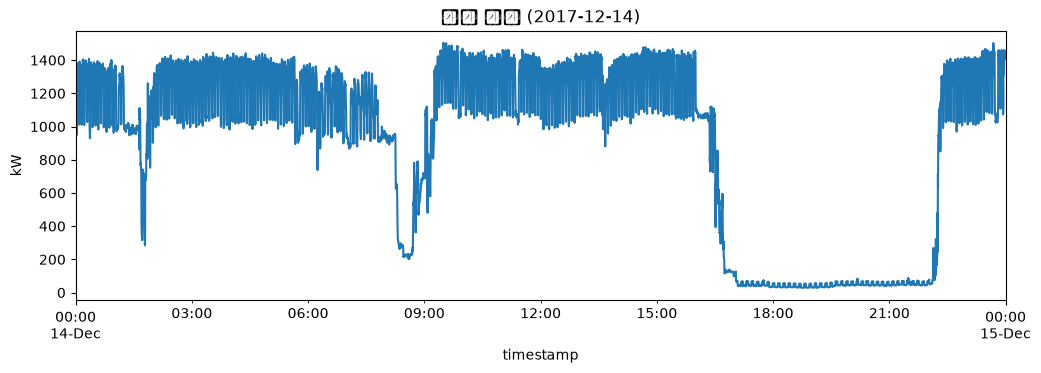

/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/

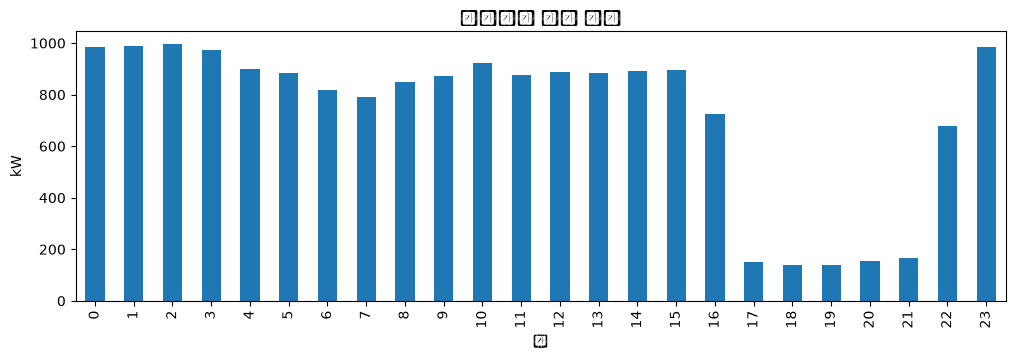

In [5]:
# 하루 예시
day = steps.index.normalize().unique()[3]
one_day = steps[day:day + pd.Timedelta(days=1)]
one_day.plot(title=f"하루 전력 ({day:%Y-%m-%d})", ylabel="kW")
plt.show()

# 시간대별 평균
hourly = steps.groupby(steps.index.hour).mean()
hourly.plot(kind="bar", title="시간대별 평균 전력", ylabel="kW", xlabel="시")
plt.show()

**확인할 것:** 가동 시간대 / 정지 시간대(원본 공장은 오후 5~10시 정지), 하루 안에서 부하가 얼마나 출렁이는지.

## 3. 15분 구간 평균 분포

/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core

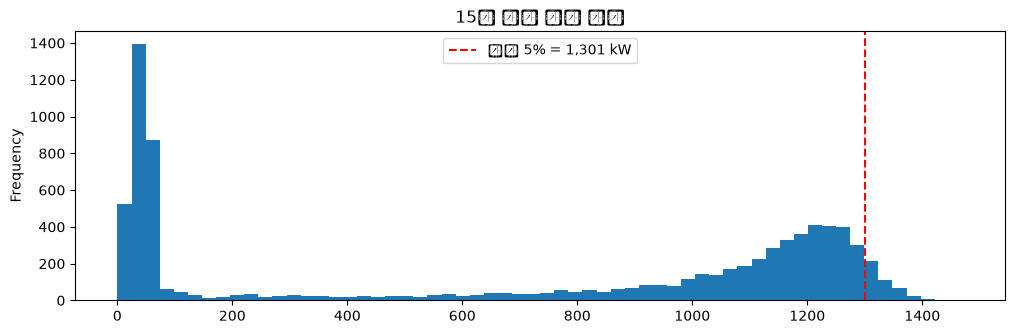

15분 평균 상위 5% 선: 1,301 kW  -> 평가용 목표전력으로 사용


In [6]:
win = steps.resample("15min").mean().dropna()
target_kw = np.percentile(win, 95)

win.plot(kind="hist", bins=60, title="15분 구간 평균 분포")
plt.axvline(target_kw, color="red", linestyle="--", label=f"상위 5% = {target_kw:,.0f} kW")
plt.legend()
plt.show()

print(f"15분 평균 상위 5% 선: {target_kw:,.0f} kW  -> 평가용 목표전력으로 사용")

시뮬레이터의 목표전력(1,600kW)은 이 데이터 기준으로 거의 넘지 않을 수 있어서, 모델 평가에서는 **학습 구간 15분 평균 상위 5%**를 목표전력으로 둔다. 그래야 "막아야 할 피크" 구간이 생겨서 놓친 피크·헛경보를 셀 수 있다.

## 4. 학습 샘플 만들기

In [7]:
df, X_seq = features.build_samples(steps)
df["split"] = features.split_by_date(df)
df["residual"] = df["actual_kw"] - df["proj_base"]

print(f"샘플 수: {len(df):,}  /  시퀀스 모양: {X_seq.shape}")
print(df["split"].value_counts())
df[["window_start", "elapsed_min", "kw_now", "proj_base", "proj_trend", "actual_kw", "residual"]].head(10)

샘플 수: 52,628  /  시퀀스 모양: (52628, 60)
split
train    36937
test      9236
valid     6455
Name: count, dtype: int64


,window_start,elapsed_min,kw_now,proj_base,proj_trend,actual_kw,residual
0,2017-12-11 18:45:00,9.0,33.454369,37.261007,33.091547,38.522312,1.261304
1,2017-12-11 18:45:00,10.0,37.235168,38.612063,35.534341,38.522312,-0.089751
2,2017-12-11 18:45:00,11.0,34.173523,37.697221,37.203051,38.522312,0.825091
3,2017-12-11 18:45:00,12.0,37.794323,38.541791,38.613176,38.522312,-0.019479
4,2017-12-11 18:45:00,13.0,38.397259,38.663255,38.770798,38.522312,-0.140943
5,2017-12-11 18:45:00,14.0,34.366718,38.231376,38.247379,38.522312,0.290936
6,2017-12-11 19:00:00,2.0,53.939991,53.309409,73.967710,48.598230,-4.711179
7,2017-12-11 19:00:00,3.0,62.422729,60.378643,87.561652,48.598230,-11.780413
8,2017-12-11 19:00:00,4.0,49.075550,49.739581,63.324688,48.598230,-1.141351
9,2017-12-11 19:00:00,5.0,49.459202,50.005261,51.057091,48.598230,-1.407031


- 샘플 1개 = "15분 구간 안의 한 시점(2분~14분, 1분 간격)에서 예측했다면"
- 정답 `actual_kw` = 그 구간의 실제 15분 평균
- 모델이 맞히는 값 `residual` = 실제 평균 − 기존 계산식 (계산식이 얼마나 틀리는지)
- 분할은 **날짜 기준** 70/15/15 (같은 구간이 학습과 시험에 섞이지 않게)

## 5. 기존 계산식의 한계

/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core

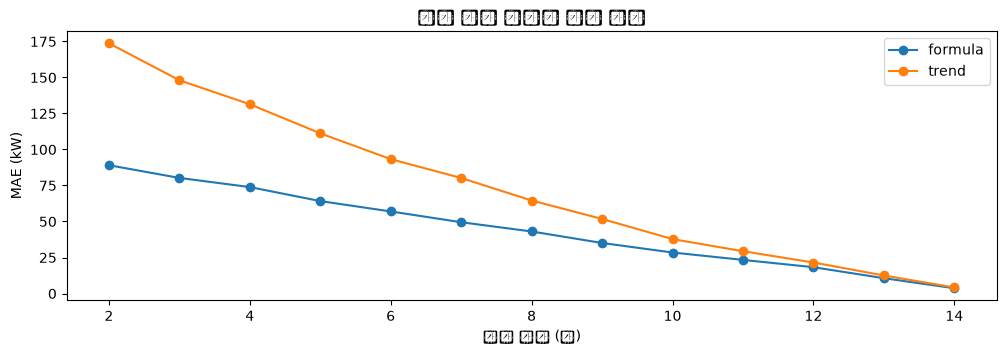

elapsed_min,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0
formula,89.1,80.3,73.9,64.2,57.0,49.5,43.1,35.1,28.5,23.3,18.3,10.6,3.7
trend,173.8,148.1,131.4,111.2,93.3,80.2,64.6,51.8,37.8,29.4,21.5,12.5,4.2


In [8]:
err = df.assign(
    formula=(df["proj_base"] - df["actual_kw"]).abs(),
    trend=(df["proj_trend"] - df["actual_kw"]).abs(),
)
by_min = err.groupby("elapsed_min")[["formula", "trend"]].mean()

by_min.plot(marker="o", title="구간 경과 시간별 예측 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()
by_min.round(1).T

**확인할 것:** 구간 초반일수록 계산식 오차가 크다. 남은 시간이 길어서 "지금 전력이 끝까지 간다"는 가정이 많이 틀리기 때문. ML 이 개선할 여지가 가장 큰 곳이 여기다.

## 6. 기본 모델 (LightGBM 기본값)

In [9]:
tr = df[df["split"] == "train"]
va = df[df["split"] == "valid"]

model = LGBMRegressor(random_state=42, verbose=-1)
model.fit(tr[TAB_COLS].to_numpy(), tr["residual"])

va_pred = va["proj_base"].to_numpy() + model.predict(va[TAB_COLS].to_numpy())

compare = pd.DataFrame({
    "기존 계산식": [(va["proj_base"] - va["actual_kw"]).abs().mean()],
    "추세 보정": [(va["proj_trend"] - va["actual_kw"]).abs().mean()],
    "LightGBM 기본값": [np.abs(va_pred - va["actual_kw"]).mean()],
}, index=["valid MAE (kW)"])
compare.round(1)

,기존 계산식,추세 보정,LightGBM 기본값
valid MAE (kW),53.8,82.7,37.1


/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core

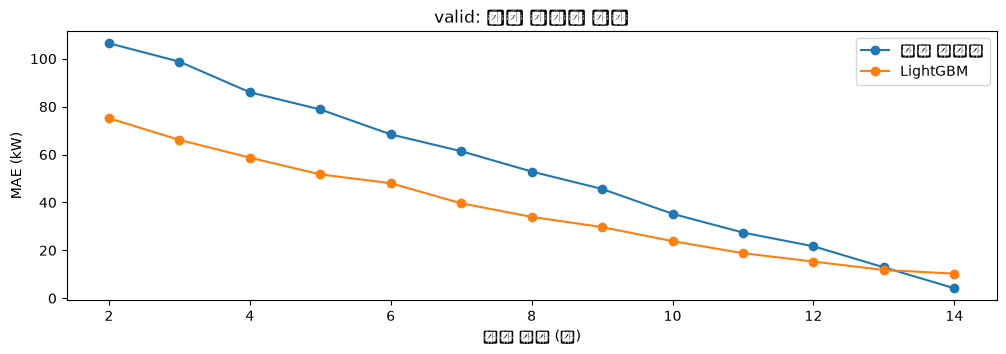

In [10]:
# 경과 시간별로 비교
va_err = pd.DataFrame({
    "elapsed_min": va["elapsed_min"].to_numpy(),
    "기존 계산식": (va["proj_base"] - va["actual_kw"]).abs().to_numpy(),
    "LightGBM": np.abs(va_pred - va["actual_kw"].to_numpy()),
}).groupby("elapsed_min").mean()

va_err.plot(marker="o", title="valid: 경과 시간별 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()

/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51669 (\N{HANGUL SYLLABLE JING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/gmlck/projects/power-edge/ml/.venv/lib/python3.14/site-packages/IPython/core

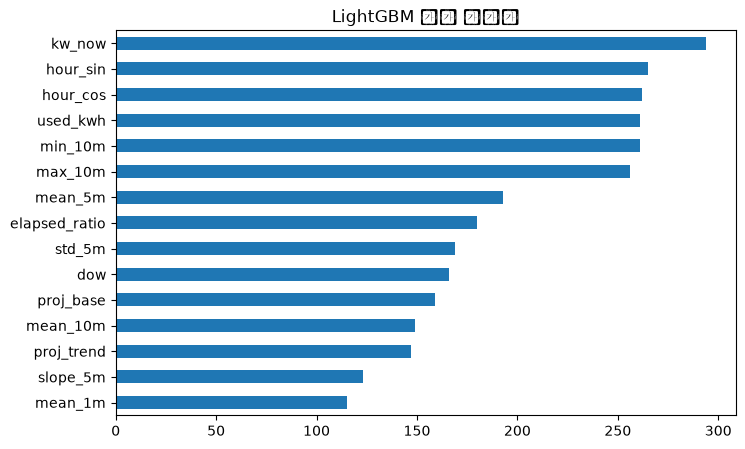

In [11]:
# 어떤 특징이 중요했나
importance = pd.Series(model.feature_importances_, index=TAB_COLS).sort_values()
importance.plot(kind="barh", title="LightGBM 특징 중요도", figsize=(8, 5))
plt.show()

## 7. 정리 (실행 후 직접 적기)

- 데이터: 
- 기존 계산식 한계: 
- 기본 모델 결과: 
- 다음 단계: `python train.py` 로 모델 6개 튜닝 + 앙상블 비교 → `outputs/results.csv`

## 8. (train.py 실행 후) 결과 확인

In [12]:
import os

if os.path.exists("outputs/results.csv"):
    results = pd.read_csv("outputs/results.csv")
    last = results[results["run_id"] == results["run_id"].max()]
    show = last[["kind", "method", "members", "valid_mae", "test_mae", "test_mae_early",
                 "missed_peaks", "false_alarms", "early_min", "selected"]]
    display(show.sort_values("valid_mae").round(1))
else:
    print("아직 train.py 를 실행하지 않았습니다.")

아직 train.py 를 실행하지 않았습니다.


In [13]:
# 몇 개 조합이 좋았나 (조합 개수별 최고 성능)
if os.path.exists("outputs/ensembles.csv"):
    ens = pd.read_csv("outputs/ensembles.csv")
    ens = ens[ens["run_id"] == ens["run_id"].max()]
    best_by_n = ens.groupby(["n_models", "method"])["valid_mae"].min().unstack()
    best_by_n.plot(marker="o", title="조합 개수별 최고 valid MAE", xlabel="모델 수", ylabel="MAE (kW)")
    plt.show()
    display(best_by_n.round(1))